<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/31_Sequence_to_Sequence_Learning_4_Machine_Translation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Why Do We Need a Seq2Seq Model?

In our earlier language-modeling examples, the RNN processed a sequence
and predicted the next token at each time step.

Machine translation is different.

We need to transform one complete sequence into another sequence:

**Source Sequence → Target Sequence**

For example:

**English:** `They are watching.`  
**French:** `Ils regardent.`

A key challenge is that the source and target sequences do **not need to
have the same length**.

The model therefore cannot simply produce one target token for every
source token.

Instead, we use the **encoder–decoder architecture** introduced in the
previous section:




## Sequence-to-Sequence Learning for Machine Translation

We now turn the **encoder–decoder architecture** into an actual
sequence-to-sequence model.

Both components can be implemented using recurrent neural networks:

**Source Sequence → RNN Encoder → Encoded State → RNN Decoder → Target Sequence**

### RNN Encoder

The encoder processes the source sequence one token at a time.

For example:

`They → are → watching → . → <eos>`

As the encoder moves through the sequence, its hidden state is updated.

The **final encoder hidden state** provides an encoded representation
of the source sequence that can be passed to the decoder.



### RNN Decoder

The decoder is a separate RNN that generates the target sequence
**one token at a time**.

Generation begins with the special token:

`<bos>`

For example:

`<bos> → Ils → regardent → . → <eos>`

The `<eos>` token tells the decoder that the output sequence is complete.

Therefore, the decoder does not need to generate the same number of
tokens as the encoder received.





### The Complete Seq2Seq Model

For machine translation:

**Encoder**

`They → are → watching → . → <eos>`

↓

**Encoded State**

↓

**Decoder**

`<bos> → Ils → regardent → . → <eos>`

The encoder and decoder therefore have different roles:

- **Encoder:** processes and represents the source sequence.
- **Decoder:** generates the target sequence one token at a time.

But this raises an important question:

> During training, what should we give the decoder as its previous token?

This leads to **teacher forcing**.

### RNN Encoder–Decoder in Action

The figure below shows how an RNN-based sequence-to-sequence model
performs translation.

The **encoder RNN** reads the source sequence one token at a time:

`They → are → watching → . → <eos>`

As it processes the sequence, its hidden state carries information
forward. The final encoder state provides information about the source
sequence to the decoder.

The **decoder RNN** then generates the target sequence one token at a time:

`<bos> → Ils → regardent → . → <eos>`

At each decoding step, the decoder uses:

- the current decoder input token,
- the previous decoder hidden state, and
- information obtained from the encoder.

The generated token becomes part of the information used to generate
the next token. Generation stops when the decoder produces `<eos>`.

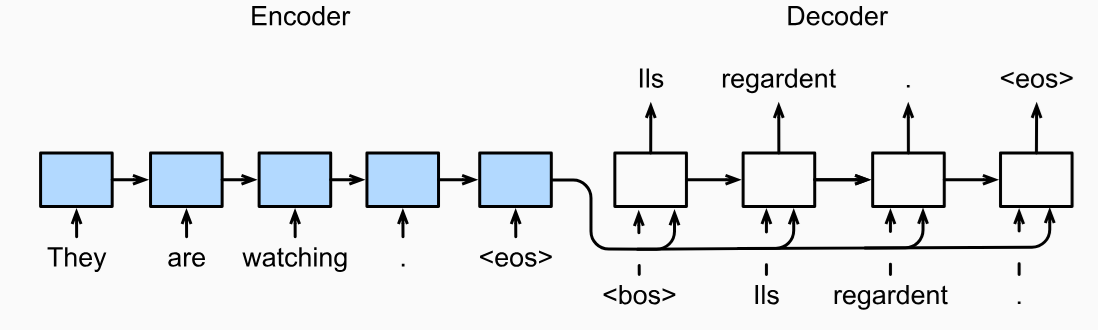

### Teacher Forcing

There is an important question when training the decoder:

> What should we give the decoder as its input at the next time step?

During training, we already know the **correct target sequence**.  
A common approach is therefore to give the decoder the **actual previous target token**, rather than the token predicted by the model.

This is called **teacher forcing**.

For example, suppose the correct target sequence is:

`Ils → regardent → . → <eos>`

The decoder training process is:

| Decoder Input | Desired Output |
|---|---|
| `<bos>` | `Ils` |
| `Ils` | `regardent` |
| `regardent` | `.` |
| `.` | `<eos>` |

Notice that the decoder input and desired output are the same target
sequence **shifted by one position**:

**Input:**

`<bos> → Ils → regardent → .`

**Target:**

`Ils → regardent → . → <eos>`



During training, the correct previous token is provided to the decoder.

During prediction, however, the correct target sequence is not available.
The decoder must use its **own previously generated token** to continue
generating the sequence.

> **Note:** The focus here is the **sequence-to-sequence architecture**, not a
> new type of recurrent cell. The encoder and decoder are shown as RNNs for
> simplicity. In practice, recurrent encoder–decoder models can also use
> GRU or LSTM cells.

## Seq2Seq Encoder

We now know the overall sequence-to-sequence architecture:

**Source Sequence → Encoder → Context → Decoder → Target Sequence**

The next question is:

> **How does the encoder convert a sequence of words into the context used by the decoder?**

Suppose the source sentence is:

`They → are → watching → . → <eos>`

The encoder processes this sequence one token at a time and gradually builds
a representation of the source sentence.

However, before an RNN or GRU can process these tokens, we must first
represent them numerically.

### From Tokens to Embeddings

Our source sequence contains tokens such as:

`They`, `are`, `watching`, `.`, `<eos>`

A neural network cannot directly perform computations on these words.

The vocabulary therefore assigns each token an integer ID.

For example:

`They → 15`

`are → 27`

`watching → 84`

But these numbers are only **identifiers**.

For example, token ID `84` does not mean that `watching` is numerically
larger or more important than `are`.

Therefore, before giving a token to the recurrent network, an
**embedding layer** converts its token ID into a learned vector of
numerical features.

For example:

`They → 15 → [0.2, -0.7, 0.1, ...]`

The values in this vector are learned during training.

Therefore, the beginning of the encoder pipeline is:

**Source Tokens → Token IDs → Embedding Vectors → GRU**

### Processing the Source Sequence

After converting the tokens into embedding vectors, the recurrent network
processes them sequentially.

For an input sequence

$$
x_1, x_2, \ldots, x_T
$$

the hidden state is updated at each time step:

$$
h_t = f(x_t, h_{t-1})
$$

where:

- $x_t$ is the embedding vector of the current source token,
- $h_{t-1}$ is the previous hidden state,
- $h_t$ is the new hidden state.

Conceptually:

`x₁ → h₁ → x₂ → h₂ → x₃ → h₃ → ... → xₜ → hₜ`

Because each hidden state depends on the previous hidden state, information
about earlier source tokens is carried forward through the sequence.

After processing the complete source sequence, the encoder has produced:

$$
h_1, h_2, \ldots, h_T
$$

These are the encoder's hidden states at the different time steps.

### The Context Variable

The encoder must provide information about the source sequence to the decoder.

We call this information the **context variable**:

$$
c = q(h_1, h_2, \ldots, h_T)
$$

where $q$ describes how the encoder hidden states are converted into the
context.

In the basic sequence-to-sequence model considered here, we can use the
final encoder hidden state:

$$
c = h_T
$$

Since $h_T$ is produced after the encoder has processed the complete source
sequence, it contains information accumulated from the source.

The complete encoder pipeline is therefore:

**Source Tokens → Token IDs → Embeddings → GRU → Hidden States → Context**

The context is then passed to the decoder to help it generate the target
sequence.

### What Recurrent Network Does the Encoder Use?

The encoder–decoder architecture does not require a particular type of
recurrent cell.

The encoder could be implemented using:

- a basic RNN,
- a GRU, or
- an LSTM.

D2L implements the encoder here using a **multilayer GRU**.

We have already studied how a GRU uses reset and update gates.

Our focus is now on how the GRU is used as a component of the larger
sequence-to-sequence architecture.

In [ ]:
!pip install --q D2l --no-deps

In [ ]:

import tensorflow as tf
from d2l import tensorflow as d2l

# English-French machine translation dataset
data = d2l.MTFraEng(batch_size=128)

### What Does the Encoder Return?

The encoder returns two objects:

#### 1. `outputs`

`outputs` contains the hidden state produced at **every time step**:

$$
h_1, h_2, \ldots, h_T
$$

For a sequence of $T$ tokens, we therefore retain a representation
associated with every position in the source sequence.

These individual encoder outputs will become especially important when we
later introduce **attention**.

#### 2. `state`

`state` contains the final hidden state of the recurrent network.

In our basic encoder–decoder model, this final state provides the context
needed to begin decoding.

Therefore:

**`outputs` → hidden states across all source time steps**

**`state` → final encoder state used by the decoder**

That is, the final state corresponds to:

$$
h_T
$$

In [ ]:
class Seq2SeqEncoder(tf.keras.layers.Layer):
    """GRU encoder for sequence-to-sequence learning."""

    def __init__(
        self,
        vocab_size,
        embed_size,
        num_hiddens,
        num_layers,
        dropout=0
    ):
        super().__init__()

        # Source token IDs -> embedding vectors
        self.embedding = tf.keras.layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_size
        )

        # Stack GRU layers
        self.gru_layers = []

        for _ in range(num_layers):
            self.gru_layers.append(
                tf.keras.layers.GRU(
                    num_hiddens,
                    return_sequences=True,
                    return_state=True,
                    dropout=dropout
                )
            )

    def call(self, X, training=False):

        # X shape:
        # (batch_size, num_steps)

        # Token IDs -> embeddings
        # (batch_size, num_steps, embed_size)
        #call defines how the encoder processes input when you use it.
        X = self.embedding(X)

        states = []

        # Pass through each GRU layer
        for gru in self.gru_layers:
            X, state = gru(
                X,
                training=training
            )

            # Final hidden state from this GRU layer
            states.append(state)

        # X:
        # hidden representations at ALL source time steps
        #
        # states:
        # final hidden state from EACH GRU layer
        return X, states

In [ ]:
# Small test of the encoder

vocab_size = 10
embed_size = 8
num_hiddens = 16
num_layers = 2

batch_size = 4
num_steps = 9

encoder = Seq2SeqEncoder(
    vocab_size,
    embed_size,
    num_hiddens,
    num_layers
)

# Artificial batch of token IDs
X = tf.zeros(
    (batch_size, num_steps),
    dtype=tf.int32
)

# Run the encoder
enc_outputs, enc_state = encoder(X)

print("Encoder outputs shape:")
print(enc_outputs.shape)

print("\nNumber of final states:")
print(len(enc_state))

print("\nFinal state shapes:")
for state in enc_state:
    print(state.shape)

Encoder outputs shape:
(4, 9, 16)

Number of final states:
2

Final state shapes:
(4, 16)
(4, 16)


## Interpreting the Encoder Output

This is a small test using artificial input.

The encoder output has shape:

`(4, 9, 16)`

where:

- **4** = sequences in the batch
- **9** = token positions in each sequence
- **16** = hidden features used to represent each position

Therefore, the encoder produces a 16-dimensional hidden representation
for every token position in every sequence.

Because our encoder contains **2 GRU layers**, each layer also has its own
final hidden state.

For each layer, the final state has shape:

`(4, 16)`

This means that each of the 4 sequences has a final 16-dimensional hidden
representation.

These final encoder states are passed to the decoder. Each decoder GRU layer
is initialized using the final hidden state from the corresponding encoder
GRU layer.

## Where We Are in the Seq2Seq Model

We have now implemented the encoder:

**Source Tokens → Embeddings → GRU Encoder → Encoder State**

The encoder reads the source sequence and produces a representation of it.

Next, we will see how the **decoder** uses this encoder state to generate
the target sequence one token at a time.

## Decoder: Generating the Target Sequence

The **decoder** uses the information produced by the encoder to generate the target sequence **one token at a time**.

For example:

`<bos> → Ils → regardent → . → <eos>`

At each step, the decoder uses:

- the **previous target token**
- the **previous decoder hidden state**
- the **encoder information**

to predict the next token.

Conceptually:

$$
s_t = g(y_{t-1}, c, s_{t-1})
$$

where:

- $y_{t-1}$ = previous target token
- $c$ = context from the encoder
- $s_{t-1}$ = previous decoder hidden state
- $s_t$ = current decoder hidden state

---




### During Training

We use **teacher forcing**:

**Decoder input:**

`<bos> → Ils → regardent → .`

**Expected output:**

`Ils → regardent → . → <eos>`

So the decoder learns to predict the **next target token** using the correct previous token and the encoder information.

## Seq2Seq Decoder Implementation

The decoder receives three things:

- the **target tokens** used as decoder input,
- the **encoder outputs**, and
- the **final encoder state**.

(X, encoder_outputs, encoder_states)

The target token IDs are first converted into embeddings.

The final encoder output provides the **context** representing the source
sequence. This context is combined with the target embeddings so that the
decoder has information about the source while processing each target
position.

The encoder state is also used to initialize the decoder hidden state.

Finally, a Dense layer converts each decoder hidden representation into
scores for every possible token in the target vocabulary.

Conceptually:

`Target Tokens → Embedding → + Encoder Context → Decoder GRU → Dense → Target-Token Scores`

and

`Final Encoder State → Initial Decoder State`

In [ ]:
class Seq2SeqDecoder(tf.keras.layers.Layer):
    """GRU decoder for sequence-to-sequence learning."""

    def __init__(
        self,
        vocab_size,
        embed_size,
        num_hiddens,
        num_layers,
        dropout=0
    ):
        super().__init__()

        # Target token IDs -> embedding vectors
        self.embedding = tf.keras.layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_size
        )

        # Stack decoder GRU layers
        self.gru_layers = []

        for _ in range(num_layers):
            self.gru_layers.append(
                tf.keras.layers.GRU(
                    num_hiddens,
                    return_sequences=True,
                    return_state=True,
                    dropout=dropout
                )
            )

        # GRU output -> scores for every target token
        self.dense = tf.keras.layers.Dense(vocab_size)

    def call(
        self,
        X,
        encoder_outputs,
        encoder_states,
        training=False
    ):

        # -------------------------------------------------
        # 1. Target token IDs -> embeddings
        # -------------------------------------------------

        # Shape:
        # (batch_size, target_steps, embed_size)
        X = self.embedding(X)


        # -------------------------------------------------
        # 2. Obtain encoder context
        # -------------------------------------------------

        # Final output of the TOP encoder GRU layer
        # Shape:
        # (batch_size, num_hiddens)
        context = encoder_outputs[:, -1, :]

        # Repeat the context for every decoder time steptf.
        #expand_dims and tf.tile are TensorFlow functions.
        #Together, these lines repeat the context vector at every decoder time step.
        #tile repeats values along dimensions
        # (batch_size, num_hiddens)
        # ->
        # (batch_size, target_steps, num_hiddens)
        context = tf.expand_dims(context, axis=1)

        context = tf.tile(
            context,
            [1, tf.shape(X)[1], 1]
        )


        # -------------------------------------------------
        # 3. Combine target embedding + encoder context
        # -------------------------------------------------

        X = tf.concat(
            [X, context],
            axis=-1
        )


        # -------------------------------------------------
        # 4. Run decoder GRUs
        # -------------------------------------------------

        new_states = []

        for i, gru in enumerate(self.gru_layers):

            # Initialize each decoder layer using the
            # corresponding final encoder hidden state
            X, state = gru(
                X,
                initial_state=encoder_states[i],
                training=training
            )

            new_states.append(state)


        # -------------------------------------------------
        # 5. Convert decoder representations to vocab scores
        # -------------------------------------------------

        # Shape:
        # (batch_size, target_steps, target_vocab_size)
        logits = self.dense(X)

        return logits, new_states

### Decoder Components

The decoder has a structure similar to the encoder, but it must also **predict target tokens**:

`Target Token → Embedding → GRU → Dense Layer → Next-Token Scores`

- **Embedding:** represents the target token.
- **GRU:** processes the sequence using the decoder hidden state.
- **Dense layer:** produces a score for every token in the target vocabulary.

The decoder also receives information from the **encoder** so that its predictions are conditioned on the source sequence.

### Connecting the Encoder to the Decoder

The decoder should not generate the translation without knowing the source sentence.

We therefore use the **final encoder state** to initialize the decoder's hidden state:

`Source → Encoder → Final Encoder State → Decoder`

The decoder then processes the target tokens starting from this encoder information.

> **Note:** `initial_state` is the **final hidden state produced by the encoder**.  
> We pass it into the decoder so that the decoder begins with information about the source sequence.
>
> `Final Encoder State → initial_state of Decoder GRU`

### Putting the Encoder and Decoder Together

The complete RNN encoder–decoder now has two sides:

- **Encoder:** `Source → Embedding → GRU`
- **Decoder:** `Target → Embedding → GRU → Dense`

The decoder receives information from the encoder in two ways:

1. The final hidden state from each encoder GRU layer initializes the corresponding decoder GRU layer.

2. The encoder's final output is used as a context vector and concatenated with the target embedding at every decoder time step.

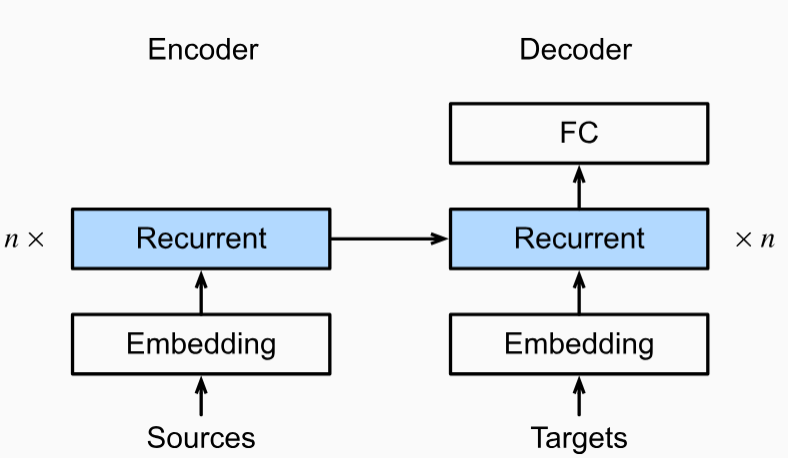

## Putting the Encoder and Decoder Together

We have now built the two components of the seq2seq model:

**Source → Encoder → Encoder State**

**Target + Encoder State → Decoder → Target-token scores**

Now we combine them into a single **Seq2Seq model**:

`Source → Encoder → Final State → Decoder → Target Predictions`

During training, the decoder receives the correct target tokens shifted by one position (**teacher forcing**).

The class below receives the **encoder object** and **decoder object** that we created earlier and packages them into one model for training and evaluation.

### Building the Complete Seq2Seq Model

So far, the encoder and decoder have been separate objects.

We now place them inside one **Seq2Seq model**:

`Source → Encoder → Encoder State → Decoder → Target Predictions`

The class below stores the encoder and decoder together so that the complete model can later be **trained and evaluated**.



In [ ]:
class Seq2Seq(tf.keras.Model):
    """Complete encoder-decoder sequence-to-sequence model."""

    def __init__(
        self,
        encoder,
        decoder,
        tgt_pad
    ):
        super().__init__()

        # Store the encoder and decoder objects
        self.encoder = encoder
        self.decoder = decoder

        # ID assigned to <pad> in the target vocabulary
        self.tgt_pad = tgt_pad

    def call(
        self,
        source,
        target_input,
        training=False
    ):

        # -------------------------------------------------
        # Encoder
        # -------------------------------------------------

        encoder_outputs, encoder_states = self.encoder(
            source,
            training=training
        )


        # -------------------------------------------------
        # Decoder
        # -------------------------------------------------

        decoder_outputs, decoder_states = self.decoder(
            target_input,
            encoder_outputs,
            encoder_states,
            training=training
        )

        return decoder_outputs

Some target sequences contain `<pad>` tokens, but predicting `<pad>` correctly should not count as learning the translation.

Therefore, we need a way to **exclude padded positions when calculating the loss**.

This leads to **loss masking**.

## Loss Function with Masking

Recall that sentences in a batch may have different lengths, so shorter sequences are padded with `<pad>` tokens.

For example:

`salut . <eos> <pad> <pad>`

The decoder still produces a prediction at **every position**, including the padded positions.

But `<pad>` is not part of the actual translation.

Therefore, predictions at `<pad>` positions should **not contribute to the loss**.

### Masking

We create a **mask**:

- Real target token → `1`
- `<pad>` token → `0`

Example:

`salut   .   <eos>   <pad>   <pad>`  
`  1     1     1       0       0`

We multiply the loss by this mask:

`token loss × mask`

Therefore, losses from `<pad>` positions become zero.

The final loss is calculated using only the **real target tokens**.

In [ ]:
# Cross-entropy at every target position
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True,
    reduction='none'
)


def masked_loss(Y, Y_hat):

    # Compute loss at every target position
    #
    # Shape:
    # (batch_size, num_steps)
    loss = loss_fn(Y, Y_hat)

    # Create mask:
    #tgt_pad is the padding token’s ID. The comparison identifies
    #non-padding positions; tf.cast converts True/`False` to 1.0/`0.0`.
    # real token -> 1
    # <pad>      -> 0
    mask = tf.cast(
        Y != tgt_pad,
        tf.float32
    )

    # Remove losses from <pad> positions
    loss = loss * mask

    # Average only over real target tokens
    return (
        tf.reduce_sum(loss)
        /
        tf.reduce_sum(mask)
    )

### What the Loss Function Does

The loss function performs three steps:

1. **Compute the loss** for every target position.
2. **Create a mask** where real target tokens are `1` and `<pad>` tokens are `0`.
3. **Average the loss only over real target tokens**.

Conceptually:

`Target tokens → Compute losses → Mask <pad> losses → Average remaining losses`

So `<pad>` positions are present in the training batch, but they do **not affect model learning**.

## Training the Seq2Seq Model

We now have the main pieces needed for training:

- an **encoder** for the source sequence,
- a **decoder** for the target sequence,
- a **masked loss** that ignores `<pad>` positions,
- the complete **Seq2Seq model** connecting the encoder and decoder,
- and an **optimizer** for updating the model parameters.

Training follows the usual process:

`Source + Target → Seq2Seq Model → Predictions → Masked Loss → Update Weights`

During training, the decoder uses **teacher forcing**: the correct previous target token is provided as input when predicting the next token.

1. Load the English–French translation data
2. Choose model sizes
3. Create encoder → decoder → complete model
4. Create the optimizer
5. Train the model

In [ ]:
# Model hyperparameters
embed_size = 256
num_hiddens = 256
num_layers = 2
dropout = 0.2


# Create encoder
encoder = Seq2SeqEncoder(
    vocab_size=len(data.src_vocab),
    embed_size=embed_size,
    num_hiddens=num_hiddens,
    num_layers=num_layers,
    dropout=dropout
)


# Create decoder
decoder = Seq2SeqDecoder(
    vocab_size=len(data.tgt_vocab),
    embed_size=embed_size,
    num_hiddens=num_hiddens,
    num_layers=num_layers,
    dropout=dropout
)


# Retrieve the ID assigned to <pad>
tgt_pad = data.tgt_vocab['<pad>']


# Complete model
model = Seq2Seq(
    encoder=encoder,
    decoder=decoder,
    tgt_pad=tgt_pad
)

print("Target <pad> ID:", tgt_pad)

Target <pad> ID: 5


###Note

**Adam** is the optimizer used to update the model parameters.

Unlike basic gradient descent, Adam tracks the recent gradients of **each parameter** and adapts its update size accordingly.

This often makes training faster and more stable.

Other options include SGD, Momentum, RMSprop, and Adagrad.

In [ ]:
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.005
)

### One Training Step

Training happens one batch at a time.

For each batch, the model performs four main steps:

**Forward Pass → Compute Loss → Compute Gradients → Update Weights**

1. **Forward pass:** the model uses the source sentence and target input to produce predictions.

2. **Compute loss:** the masked loss measures how different the predictions are from the correct target tokens while ignoring `<pad>` positions.

3. **Compute gradients:** the gradients indicate how the model parameters should change to reduce the loss.

4. **Update weights:** the optimizer uses these gradients to update the model parameters.

This process is repeated for every batch during training.

In [ ]:
@tf.function
def train_step(source, target_input, label):

    with tf.GradientTape() as tape:

        # Teacher forcing:
        # target_input contains the correct previous target tokens
        predictions = model(
            source,
            target_input,
            training=True
        )

        # Ignore <pad> positions when computing loss
        loss = masked_loss(
            label,
            predictions
        )

    # Compute gradients for the complete encoder-decoder model
    gradients = tape.gradient(
        loss,
        model.trainable_variables
    )

    # Gradient clipping
    gradients, _ = tf.clip_by_global_norm(
        gradients,
        1.0
    )

    # Update model parameters
    optimizer.apply_gradients(
        zip(
            gradients,
            model.trainable_variables
        )
    )

    return loss

In [ ]:
num_epochs = 30

for epoch in range(num_epochs):

    total_loss = 0.0
    num_batches = 0

    for batch in data.train_dataloader():

        # D2L translation batch:
        #
        # source       = English token IDs
        # target_input = French decoder input
        # source_len   = valid source lengths
        # label        = correct French next tokens
        source, target_input, source_len, label = batch

        loss = train_step(
            source,
            target_input,
            label
        )

        total_loss += float(loss)
        num_batches += 1

    avg_loss = total_loss / num_batches

    print(
        f"Epoch {epoch + 1:2d}/{num_epochs} "
        f"- loss: {avg_loss:.4f}"
    )

Epoch  1/30 - loss: 4.7433
Epoch  2/30 - loss: 3.3311
Epoch  3/30 - loss: 2.9355
Epoch  4/30 - loss: 2.7668
Epoch  5/30 - loss: 2.5690
Epoch  6/30 - loss: 2.2741
Epoch  7/30 - loss: 2.0282
Epoch  8/30 - loss: 1.8152
Epoch  9/30 - loss: 1.6516
Epoch 10/30 - loss: 1.5207
Epoch 11/30 - loss: 1.3896
Epoch 12/30 - loss: 1.2828
Epoch 13/30 - loss: 1.1917
Epoch 14/30 - loss: 1.1069
Epoch 15/30 - loss: 1.0250
Epoch 16/30 - loss: 0.9390
Epoch 17/30 - loss: 0.8526
Epoch 18/30 - loss: 0.7960
Epoch 19/30 - loss: 0.7284
Epoch 20/30 - loss: 0.6734
Epoch 21/30 - loss: 0.6050
Epoch 22/30 - loss: 0.5749
Epoch 23/30 - loss: 0.5279
Epoch 24/30 - loss: 0.4845
Epoch 25/30 - loss: 0.4620
Epoch 26/30 - loss: 0.4413
Epoch 27/30 - loss: 0.4152
Epoch 28/30 - loss: 0.3867
Epoch 29/30 - loss: 0.3692
Epoch 30/30 - loss: 0.3466


In [ ]:
def translate(text):
    # Get the English and French vocabularies
    src, tgt = data.src_vocab, data.tgt_vocab

    # Convert English tokens to IDs and add the end token
    x = tf.constant([src[text.lower().split() + ['<eos>']]])

    # Start the French sequence with the beginning token
    y = [tgt['<bos>']]

    # Generate up to 20 French tokens
    for _ in range(20):
        # Predict using the English input and French tokens so far
        scores = model(x, tf.constant([y]), training=False)

        # Select the most likely next token
        token = int(tf.argmax(scores[0, -1]).numpy())

        # Stop when the decoder predicts the end token
        if token == tgt['<eos>']:
            break

        y.append(token)

    # Convert French IDs to text, excluding the beginning token
    return ' '.join(tgt.to_tokens(y[1:]))

print(translate("hi ."))

salut !


## Seq2Seq RNN: Recap

A sequence-to-sequence RNN uses two components:

**Encoder**
- Reads the source sequence.
- Produces hidden representations and final hidden states.

**Decoder**
- Uses information from the encoder.
- Generates predictions for the target sequence.

The overall process is:

`Source → Encoder → Encoder Information → Decoder → Target Predictions`

During **training**:

- The decoder receives the correct previous target token (**teacher forcing**).
- `<pad>` positions are ignored when calculating the loss.
- The loss is used to update both the encoder and decoder.

The key idea is that the encoder and decoder allow the **input and output sequences to have different lengths**.

However, basic seq2seq RNNs rely heavily on a fixed encoder representation of the source sequence, which can become a limitation for longer sequences.

This motivates **attention**, where the decoder can directly access relevant encoder information while generating each output token.

### Your Task

Conduct **3 experiments** with the Seq2Seq model.

For each experiment:

1. Choose **one** setting from the table below.
2. Change only that setting.
3. Retrain the model for **30 epochs**.
4. Record the **training loss at Epoch 30**.
5. Compare the loss with the baseline model.

| Setting | Suggested Change |
|---|---|
| Embedding size | `256 → 128` |
| Hidden units | `256 → 128` |
| GRU layers | `2 → 1` |
| Dropout | `0.2 → 0` |
| Learning rate | `0.005 → 0.001` |
| Optimizer | `Adam → SGD` |

**Important:** Change only **one setting per experiment** so that you can
observe the effect of that particular change.

### What to Submit

Submit **one Word document through Brightspace** containing:

#### 1. Experiment Results

For each experiment, report the setting you changed and the **training loss
reported at Epoch 30**.

| Experiment | Setting Changed | Original Value | New Value | Loss at Epoch 30 |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |

#### 2. Evidence

Include a **screenshot of the final training output** for each experiment
showing the Epoch 30 loss.

#### 3. Reflection

In **3–5 sentences**, answer:

**Which of your three changes had the largest effect on the final training
loss compared with the baseline model? Why do you think this change had
that effect?**